# Multi-Class Blob Classification Benchmark: PyTorch vs. KNN vs. K-Means

This notebook benchmarks a **PyTorch Neural Network (MLP)** against **K-Nearest Neighbors (KNN)** and unsupervised **K-Means Clustering** on 2D synthetic blob clusters.

> *Foundational PyTorch workflow adapted from Daniel Bourke's 26-hour FreeCodeCamp PyTorch course, with custom extensions benchmarking classical ML (KNN) and unsupervised clustering (K-Means).*


In [3]:
import requests
from pathlib import Path

# Download the helper functions file
url = "https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py"

if not Path("helper_functions.py").is_file():
    response = requests.get(url)
    response.raise_for_status()

    with open("helper_functions.py", "wb") as f:
        f.write(response.content)

from helper_functions import plot_decision_boundary

tensor([[ 4.4111, -1.3765],
        [ 5.6037,  3.3245],
        [-9.2845, -9.2341],
        [-8.9343,  5.5750],
        [-5.2934,  5.8425]]) tensor([1, 1, 2, 3, 3])


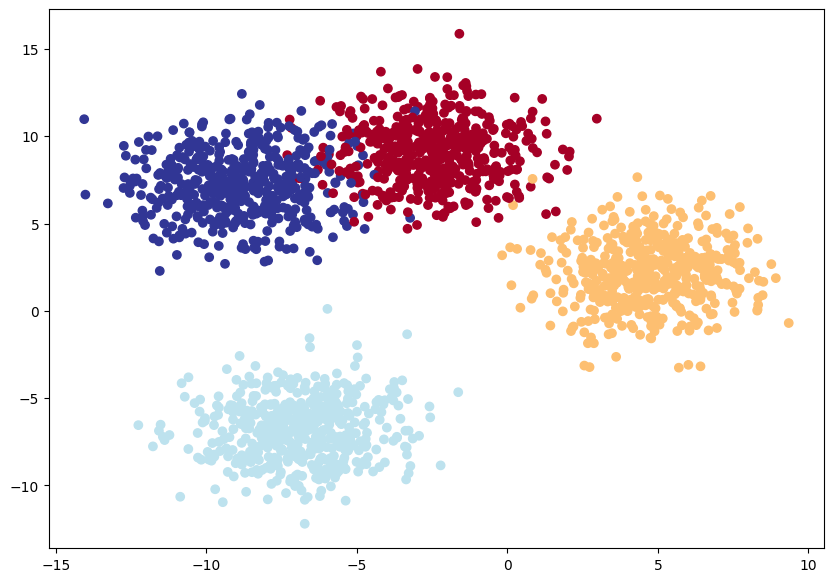

In [4]:
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

# Set the hyperparameters for data creation
NUM_CLASSES = 4
NUM_FEATURES = 2
RANDOM_SEED = 42

X_blob, y_blob = make_blobs(n_samples=2000,
    n_features=NUM_FEATURES, # X features
    centers=NUM_CLASSES, # y labels
    cluster_std=1.78, # give the clusters a little shake up (try changing this to 1.0, the default)
    random_state=RANDOM_SEED
)

# 2. Turn data into tensors
X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.LongTensor)
print(X_blob[:5], y_blob[:5])

# 3. Split into train and test sets
X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(X_blob,
    y_blob,
    test_size=0.2,
    random_state=RANDOM_SEED
)

# 4. Plot data
plt.figure(figsize=(10, 7))
plt.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap=plt.cm.RdYlBu);

In [5]:
# Create device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [6]:
from torch import nn

# Build model
class BlobModel(nn.Module):
    def __init__(self, input_features, output_features, hidden_units=8):
        super().__init__()
        self.linear_layer_stack = nn.Sequential(
            nn.Linear(in_features=input_features, out_features=hidden_units),
            nn.Linear(in_features=hidden_units, out_features=hidden_units),
            nn.Linear(in_features=hidden_units, out_features=output_features),
        )

    def forward(self, x):
        return self.linear_layer_stack(x)

model = BlobModel(input_features=NUM_FEATURES,
                    output_features=NUM_CLASSES,
                    hidden_units=8).to(device)
model

BlobModel(
  (linear_layer_stack): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): Linear(in_features=8, out_features=8, bias=True)
    (2): Linear(in_features=8, out_features=4, bias=True)
  )
)

In [7]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(),
                            lr=0.1)

In [8]:
model(X_blob_train.to(device))[:5]

tensor([[ 0.7208,  1.5333, -3.3590, -3.8573],
        [-0.4016, -2.3979,  1.7570,  1.4595],
        [ 0.6793,  1.4096, -3.1210, -3.5941],
        [ 0.5193,  0.7774, -2.5547, -3.0581],
        [ 0.1713, -0.4567, -1.0020, -1.4553]], device='cuda:0',
       grad_fn=<SliceBackward0>)

In [9]:
model(X_blob_train.to(device))[0].shape, NUM_CLASSES

(torch.Size([4]), 4)

In [10]:
y_logits = model(X_blob_test.to(device))

y_pred_probs = torch.softmax(y_logits, dim=1)
print(y_logits[:5])
print(y_pred_probs[:5])

tensor([[-0.0043, -1.2756, -0.6628, -1.2513],
        [ 0.6998,  2.1236, -1.7613, -1.7135],
        [ 0.5543,  0.9345, -2.6357, -3.1170],
        [ 0.7914,  2.3922, -2.2974, -2.3087],
        [ 0.5181,  0.8919, -2.2804, -2.6865]], device='cuda:0',
       grad_fn=<SliceBackward0>)
tensor([[0.4795, 0.1345, 0.2482, 0.1378],
        [0.1877, 0.7795, 0.0160, 0.0168],
        [0.3954, 0.5783, 0.0163, 0.0101],
        [0.1654, 0.8197, 0.0075, 0.0074],
        [0.3914, 0.5688, 0.0238, 0.0159]], device='cuda:0',
       grad_fn=<SliceBackward0>)


In [11]:
torch.sum(y_pred_probs[0])

tensor(1., device='cuda:0', grad_fn=<SumBackward0>)

In [12]:
print(y_pred_probs[0])
print(torch.argmax(y_pred_probs[0]))

tensor([0.4795, 0.1345, 0.2482, 0.1378], device='cuda:0',
       grad_fn=<SelectBackward0>)
tensor(0, device='cuda:0')


In [13]:
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc

In [14]:
torch.manual_seed(42)
epochs = 100

X_blob_train, y_blob_train = X_blob_train.to(device), y_blob_train.to(device)
X_blob_test, y_blob_test = X_blob_test.to(device), y_blob_test.to(device)

for epoch in range(epochs):
    model.train()

    y_logits = model(X_blob_train) # model outputs raw logits
    y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1)
    loss = loss_fn(y_logits, y_blob_train)
    acc = accuracy_fn(y_true=y_blob_train,
                      y_pred=y_pred)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    model.eval()
    with torch.inference_mode():
      test_logits = model(X_blob_test)
      test_pred = torch.softmax(test_logits, dim=1).argmax(dim=1)

      test_loss = loss_fn(test_logits, y_blob_test)
      test_acc = accuracy_fn(y_true=y_blob_test,
                             y_pred=test_pred)

    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%")

Epoch: 0 | Loss: 3.24433, Acc: 23.50% | Test Loss: 0.95439, Test Acc: 49.75%
Epoch: 10 | Loss: 0.21357, Acc: 97.50% | Test Loss: 0.18916, Test Acc: 97.75%
Epoch: 20 | Loss: 0.11740, Acc: 97.62% | Test Loss: 0.10806, Test Acc: 98.00%
Epoch: 30 | Loss: 0.09087, Acc: 97.69% | Test Loss: 0.08360, Test Acc: 98.00%
Epoch: 40 | Loss: 0.07950, Acc: 97.75% | Test Loss: 0.07256, Test Acc: 98.00%
Epoch: 50 | Loss: 0.07351, Acc: 97.69% | Test Loss: 0.06649, Test Acc: 98.00%
Epoch: 60 | Loss: 0.06995, Acc: 97.69% | Test Loss: 0.06272, Test Acc: 98.25%
Epoch: 70 | Loss: 0.06766, Acc: 97.69% | Test Loss: 0.06019, Test Acc: 98.25%
Epoch: 80 | Loss: 0.06608, Acc: 97.69% | Test Loss: 0.05838, Test Acc: 98.25%
Epoch: 90 | Loss: 0.06495, Acc: 97.75% | Test Loss: 0.05703, Test Acc: 98.25%


In [15]:
model.eval()
with torch.inference_mode():
    y_logits = model(X_blob_test)

y_logits[:10]

tensor([[  7.6387,  -0.3036, -10.7102,   0.5034],
        [-10.2925, -17.9004,  13.0293,   5.8621],
        [  0.6833, -17.1349,  -2.1991,   6.6756],
        [-10.0303, -21.2148,  12.4333,   7.2450],
        [ -0.3685, -15.4518,  -0.6174,   5.8790],
        [  0.8213, -14.7124,  -2.2225,   5.6987],
        [  0.7378,   5.2760,  -0.7130,  -2.4878],
        [  1.9638,   6.8708,  -2.3088,  -3.0144],
        [  0.6851, -16.0158,  -2.1236,   6.2179],
        [  4.2583,  -5.1738,  -6.3430,   2.1489]], device='cuda:0')

In [16]:
y_pred_probs = torch.softmax(y_logits, dim=1)

y_preds = y_pred_probs.argmax(dim=1)

print(f"Predictions: {y_preds[:10]}\nLabels: {y_blob_test[:10]}")
print(f"Test accuracy: {accuracy_fn(y_true=y_blob_test, y_pred=y_preds)}%")

Predictions: tensor([0, 2, 3, 2, 3, 3, 1, 1, 3, 0], device='cuda:0')
Labels: tensor([0, 2, 3, 2, 3, 3, 1, 1, 3, 0], device='cuda:0')
Test accuracy: 98.25%


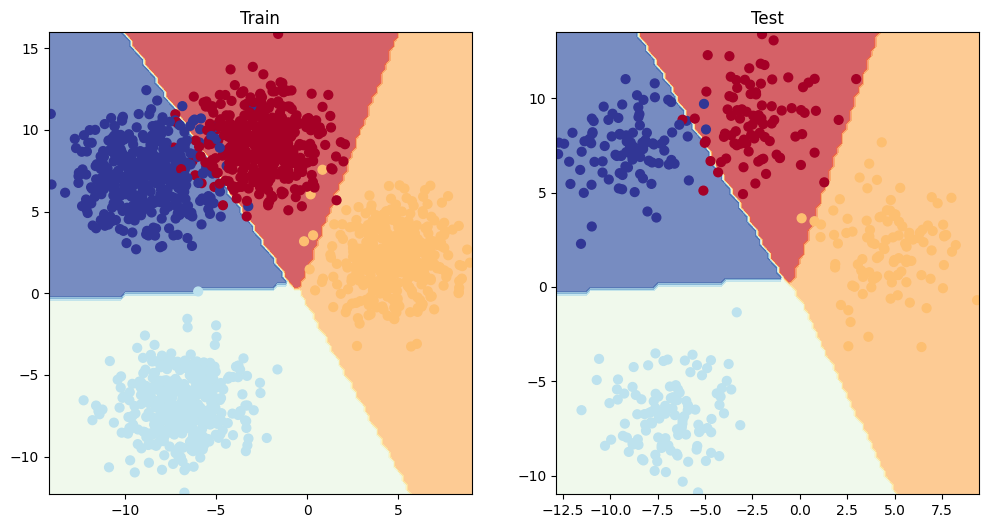

In [17]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model, X_blob_train, y_blob_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model, X_blob_test, y_blob_test)

#Using K- Means Clustering to predict blobs

In [18]:
from sklearn.cluster import KMeans

tensor([[ 4.4436,  1.8396],
        [-2.2096,  9.6809],
        [ 4.3235,  4.3517],
        [-3.8177,  6.5538],
        [ 7.4657, -0.0100]]) tensor([4, 0, 1, 0, 1])


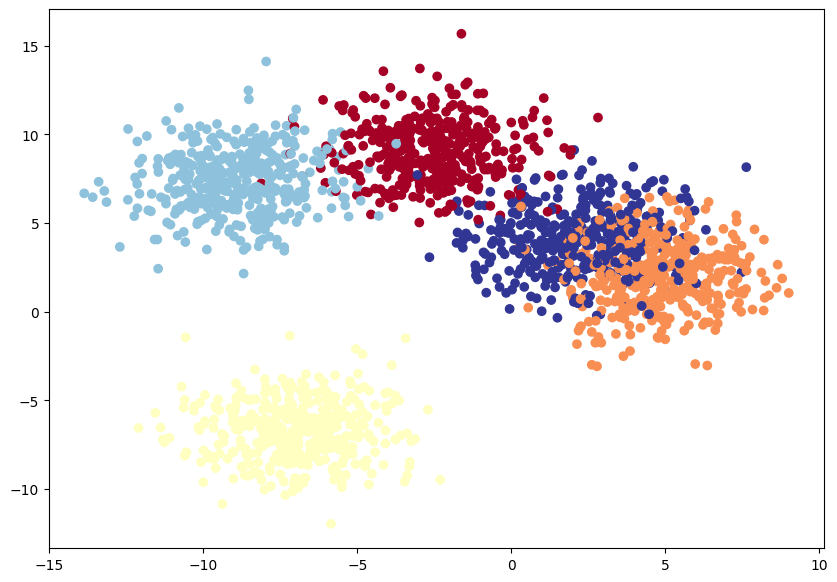

In [19]:
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

NUM_CLASSES = 5
NUM_FEATURES = 2
RANDOM_SEED = 42

X_blob, y_blob = make_blobs(n_samples=2000,
    n_features=NUM_FEATURES, # X features
    centers=NUM_CLASSES, # y labels
    cluster_std=1.73,
    random_state=42
)

X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.LongTensor)
print(X_blob[:5], y_blob[:5])

X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(X_blob,
    y_blob,
    test_size=0.2,
    random_state=42
)

plt.figure(figsize=(10, 7))
plt.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap=plt.cm.RdYlBu);

In [20]:
km = KMeans(n_clusters=5,random_state=42,n_init=10)
cluster_labels = km.fit_predict(X_blob.numpy())
print(cluster_labels[:20])

[1 0 3 0 1 4 0 2 1 4 4 0 2 4 2 4 4 2 4 1]


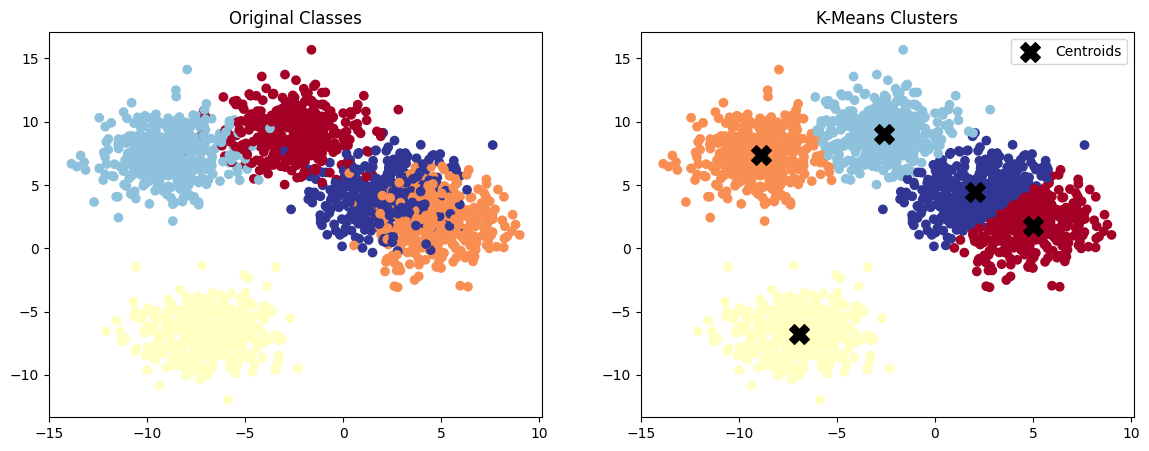

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score, silhouette_score

X_all = X_blob.numpy()
y_all = y_blob.numpy()

X_train = X_blob_train.numpy()
X_test = X_blob_test.numpy()
y_test = y_blob_test.numpy()

km.fit(X_train)

all_clusters = km.predict(X_all)
test_clusters = km.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    X_all[:, 0], X_all[:, 1],
    c=y_all, cmap=plt.cm.RdYlBu
)
axes[0].set_title("Original Classes")

axes[1].scatter(
    X_all[:, 0], X_all[:, 1],
    c=all_clusters, cmap=plt.cm.RdYlBu
)
axes[1].scatter(
    km.cluster_centers_[:, 0],
    km.cluster_centers_[:, 1],
    marker="X", s=200, c="black", label="Centroids"
)
axes[1].set_title("K-Means Clusters")
axes[1].legend()

plt.show()

In [22]:
ari = adjusted_rand_score(y_test, test_clusters)
silhouette = silhouette_score(X_test, test_clusters)

print("Adjusted Rand Index:", ari)
print("Silhouette Score:", silhouette)

Adjusted Rand Index: 0.8217435899772316
Silhouette Score: 0.5203815


#Using KNN to predict the blobs

In [25]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_blob_train.cpu().numpy(), y_blob_train.cpu().numpy())

y_pred = knn.predict(X_blob_test.cpu().numpy())

print("Accuracy:", accuracy_score(y_blob_test.cpu().numpy(), y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_blob_test.cpu().numpy(), y_pred))
print("\nClassification Report:\n", classification_report(y_blob_test.cpu().numpy(), y_pred))

Accuracy: 0.9175

Confusion Matrix:
 [[79  0  0  3  1]
 [ 0 53  0  0 10]
 [ 0  0 69  0  0]
 [ 1  0  0 86  0]
 [ 1 17  0  0 80]]

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.95      0.96        83
           1       0.76      0.84      0.80        63
           2       1.00      1.00      1.00        69
           3       0.97      0.99      0.98        87
           4       0.88      0.82      0.85        98

    accuracy                           0.92       400
   macro avg       0.92      0.92      0.92       400
weighted avg       0.92      0.92      0.92       400



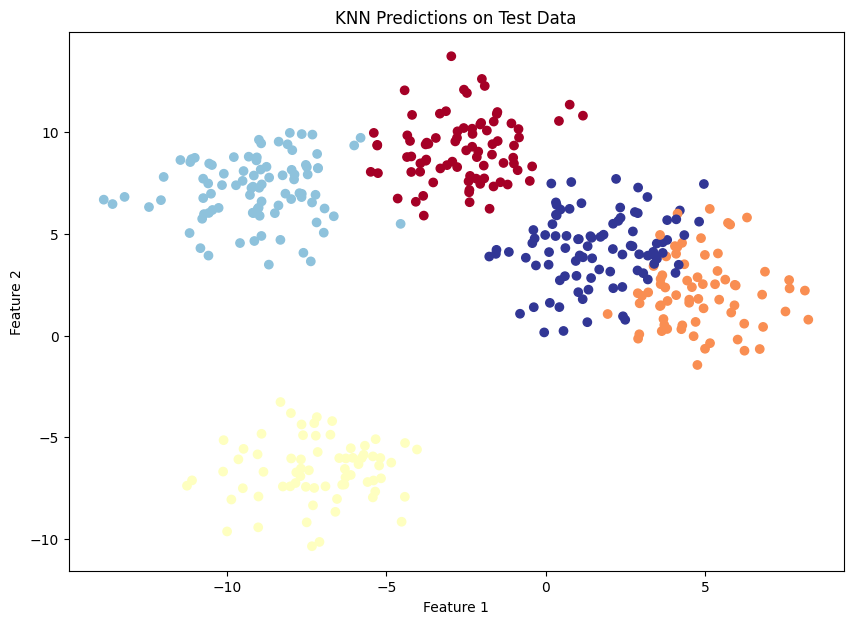

In [26]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_blob_test[:, 0],
    X_blob_test[:, 1],
    c=y_pred,
    cmap=plt.cm.RdYlBu
)

plt.title("KNN Predictions on Test Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [27]:
import pandas as pd
# Benchmark comparison table
results = pd.DataFrame({
    "Model": [
        "PyTorch Neural Network (MLP)",
        "K-Nearest Neighbors (KNN, k=5)",
        "K-Means Clustering (k=5)"
    ],
    "Paradigm": [
        "Supervised (Deep Learning)",
        "Supervised (Classical ML)",
        "Unsupervised Learning"
    ],
    "Evaluation Metric": [
        "Test Accuracy: 98.25%",
        "Test Accuracy: 91.75%",
        "Adjusted Rand Index: 0.82 (Silhouette: 0.52)"
    ],
    "Key Takeaways": [
        "Learns optimal decision boundaries via gradient descent; highest accuracy.",
        "Solid baseline; fast to fit, but sensitive to cluster overlap.",
        "Successfully discovered cluster groupings without any ground truth labels."
    ]
})
display(results)

,Model,Paradigm,Evaluation Metric,Key Takeaways
0,PyTorch Neural Network (MLP),Supervised (Deep Learning),Test Accuracy: 98.25%,Learns optimal decision boundaries via gradien...
1,"K-Nearest Neighbors (KNN, k=5)",Supervised (Classical ML),Test Accuracy: 91.75%,"Solid baseline; fast to fit, but sensitive to ..."
2,K-Means Clustering (k=5),Unsupervised Learning,Adjusted Rand Index: 0.82 (Silhouette: 0.52),Successfully discovered cluster groupings with...
